# Workshop C: Technology Professionals' Salaries

**PROG8431 — Transformation and Linear Regression**

| Team Member | Student ID |
|---|---|
| Senay Teweldebrhan | 9120588 |
| Juan Camilo Chirivi | 9115141 |
| Zeynep Ozdemir | 9045142 |

**GitHub:** [Workshop C – Data Analysis](https://github.com/jcamillochirivi/WorkshopC_DataAnalysis.git)

**Research Question:** How are professional experience, job characteristics, and country-level economic conditions related to the annual salaries of technology professionals?

**Objective:** The objective of this study is to identify the factors associated with annual salary and develop regression models to predict salary in USD.

**Data Sources:** We combine the Stack Overflow 2024 Developer Survey with World Bank indicators to include both professional information and country-level economic conditions.

**Methodology:** Following the methods demonstrated in class, we use Simple Linear Regression (SLR) and Multiple Linear Regression (MLR) with Ordinary Least Squares (OLS).

We split the dataset into 80% training data and 20% testing data using a random seed of 6174. We also apply backward elimination with a significance level of 0.05 to select the variables for our final model.

## 1. Setup and Configuration

We import the required Python libraries for data cleaning,
visualization, statistical analysis, and regression modeling.
We also define the main settings to ensure consistent and
reproducible results.

In [1]:
import importlib.util
import subprocess
import sys

packages = {"pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib",
            "scipy": "scipy", "sklearn": "scikit-learn", "statsmodels": "statsmodels",
            "IPython": "ipython"}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp, chi2_contingency, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
import statsmodels.api as sm
from IPython.display import display, Markdown

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True})
YEAR, SEED, TEST_SIZE = 2024, 6174, 0.20
MIN_SALARY, MAX_SALARY = 1_000, 500_000

### 1.1 Country and Indicator Settings

We standardize country names to combine the Stack Overflow
and World Bank datasets correctly.

We select GDP per capita, internet usage, broadband subscriptions,
and unemployment rate to study how country-level conditions
are related to annual salary.

In [2]:
COUNTRY_NAMES = {'United States of America': 'United States',
 'United Kingdom of Great Britain and Northern Ireland': 'United Kingdom',
 'South Korea': 'Korea, Rep.',
 'Republic of Korea': 'Korea, Rep.',
 'Czech Republic': 'Czechia',
 'Turkey': 'Turkiye',
 'Egypt': 'Egypt, Arab Rep.',
 'Iran, Islamic Republic of...': 'Iran, Islamic Rep.',
 'Venezuela, Bolivarian Republic of...': 'Venezuela, RB',
 'Kyrgyzstan': 'Kyrgyz Republic',
 'Slovakia': 'Slovak Republic',
 'Republic of Moldova': 'Moldova',
 'Republic of North Macedonia': 'North Macedonia',
 'Swaziland': 'Eswatini',
 'Cape Verde': 'Cabo Verde',
 'Bahamas': 'Bahamas, The',
 'Hong Kong (S.A.R.)': 'Hong Kong SAR, China',
 'Libyan Arab Jamahiriya': 'Libya',
 'United Republic of Tanzania': 'Tanzania',
 'Yemen': 'Yemen, Rep.',
 'Saint Kitts and Nevis': 'St. Kitts and Nevis',
 "Côte d'Ivoire": "Cote d'Ivoire",
 'Democratic Republic of the Congo': 'Congo, Dem. Rep.',
 'Congo, Republic of the...': 'Congo, Rep.',
 "Lao People's Democratic Republic": 'Lao PDR',
 'Micronesia, Federated States of...': 'Micronesia, Fed. Sts.',
 'Palestine': 'West Bank and Gaza',
 'North Korea': "Korea, Dem. People's Rep.",
 "Democratic People's Republic of Korea": "Korea, Dem. People's Rep."}

INDICATORS = {'NY.GDP.PCAP.CD': 'GDPPerCapita10k',
 'IT.NET.USER.ZS': 'InternetUsersPct',
 'IT.NET.BBND.P2': 'BroadbandPer100',
 'SL.UEM.TOTL.ZS': 'UnemploymentPct'}

### 1.2 Technology Settings

We select relevant programming languages, databases, cloud
platforms, and development tools from the survey.

We convert these technologies into binary variables, where
1 means reported and 0 means not reported. This allows us
to include technology information in our regression models.

In [3]:
TECHNOLOGIES = {'LanguageHaveWorkedWith': {'Python': 'ReportedPython',
                            'JavaScript': 'ReportedJavaScript',
                            'TypeScript': 'ReportedTypeScript',
                            'SQL': 'ReportedSQL',
                            'Java': 'ReportedJava',
                            'C#': 'ReportedCSharp',
                            'C++': 'ReportedCPP',
                            'Go': 'ReportedGo'},
 'DatabaseHaveWorkedWith': {'PostgreSQL': 'ReportedPostgreSQL',
                            'MySQL': 'ReportedMySQL',
                            'MongoDB': 'ReportedMongoDB',
                            'Redis': 'ReportedRedis'},
 'PlatformHaveWorkedWith': {'Amazon Web Services (AWS)': 'ReportedAWS',
                            'Microsoft Azure': 'ReportedAzure',
                            'Google Cloud': 'ReportedGoogleCloud'},
 'ToolsTechHaveWorkedWith': {'Docker': 'ReportedDocker', 'Kubernetes': 'ReportedKubernetes'}}

## 2. Load and combine the files
`DataLoader` reads the two sources and matches each respondent to one country-year. It checks that the join does not duplicate respondents. Regional totals do not match survey countries. Unmatched names are shown instead of guessing a match.

In [4]:
class DataLoader:
    """Read the CSVs and add country information to each respondent."""

    def __init__(self, data_dir):
        self.data_dir = data_dir

    def load(self):
        survey = pd.read_csv(self.data_dir / "stackoverflow_2024.csv", low_memory=False)
        files = list(self.data_dir.glob("*_Data.csv"))
        if len(files) != 1:
            raise ValueError("Keep exactly one World Bank _Data.csv in data/.")
        wb = pd.read_csv(files[0]).dropna(subset=["Country Code", "Series Code"])
        wb = wb[wb["Series Code"].isin(INDICATORS)].copy()
        wb["Value"] = pd.to_numeric(wb[f"{YEAR} [YR{YEAR}]"], errors="coerce")
        wb = wb.pivot(index="Country Name", columns="Series Code", values="Value")
        wb = wb.rename(columns=INDICATORS)
        wb["GDPPerCapita10k"] /= 10_000
        survey["CountryMatch"] = survey.Country.replace(COUNTRY_NAMES)
        self.unmatched = survey.loc[~survey.CountryMatch.isin(wb.index), "Country"].value_counts()
        # This file contains one survey year and one World Bank year.
        self.merged = survey.merge(wb, left_on="CountryMatch", right_index=True,
                                   how="left", validate="many_to_one")
        assert len(self.merged) == len(survey)
        print(f"Loaded {len(survey):,} survey responses and four {YEAR} country indicators.")
        return self.merged

### 2.1 Read the project data
The path works from the project root or the `notebooks` folder. Keep the survey filename and the extracted World Bank file ending in `_Data.csv`. The metadata CSV is documentation and is not used as respondent data.

In [5]:
DATA_DIR = next((p for p in [Path.cwd()/"data", Path.cwd().parent/"data"]
                 if (p/"stackoverflow_2024.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Put the source CSVs in the project's data/ folder.")
loader = DataLoader(DATA_DIR)
merged = loader.load()
print("Unmatched country names (excluded later if required values are missing):")
display(loader.unmatched.rename("Responses").to_frame())

Loaded 65,437 survey responses and four 2024 country indicators.
Unmatched country names (excluded later if required values are missing):


,Responses
Country,
Taiwan,268
Nomadic,43
Somalia,9
Nauru,1


## 3. Prepare the study table
`DataPreparer` cleans records and creates the predictors. We keep respondents who selected only full-time employment, have the required experience/country values and report **USD 1,000–500,000** annually. We exclude inconsistent coding-year answers. These rules define a restricted study population; they do not prove that excluded salaries are errors.

Experience text becomes a number. Optional categories use `Unknown`. Company size becomes Small (2–99), Medium (100–999), Large (1,000+) or Unknown; related roles are grouped. IDs, year and raw compensation `CompTotal` are not predictors.

In [6]:
class DataPreparer:
    """Clean responses and create a small, fixed set of study variables."""

    def build(self, merged):
        d = merged.drop_duplicates("ResponseId").copy()
        d["SalaryUSD"] = pd.to_numeric(d.ConvertedCompYearly, errors="coerce")
        for source, name in [("YearsCodePro", "ExperienceYears"), ("YearsCode", "CodingYears")]:
            d[name] = pd.to_numeric(d[source].replace(
                {"Less than 1 year": "0.5", "More than 50 years": "51"}), errors="coerce")
        self.numeric = ["ExperienceYears", "CodingYears", *INDICATORS.values()]
        rules = [(d.Employment.eq("Employed, full-time"), "Full-time employment only"),
                 (d.SalaryUSD.between(MIN_SALARY, MAX_SALARY), "Salary in stated range"),
                 (d[self.numeric].notna().all(axis=1), "Required values available"),
                 (d.CodingYears >= d.ExperienceYears, "Consistent coding years")]
        self.audit = []
        for mask, description in rules:
            before = len(d)
            d = d.loc[mask.reindex(d.index)].copy()
            self.audit.append({"Rule": description, "Removed": before-len(d), "Remaining": len(d)})
        study = d[["ResponseId", "Country", "SalaryUSD", *self.numeric]].copy()
        for source, choices in TECHNOLOGIES.items():
            answered = source.replace("HaveWorkedWith", "Answered")
            study[answered] = d[source].notna().astype(int)
            self.numeric.append(answered)
            answers = d[source].fillna("").str.split(";")
            for technology, name in choices.items():
                study[name] = answers.map(lambda items: int(technology in items))
                self.numeric.append(name)
        study["Education"] = d.EdLevel.fillna("Unknown")
        study["WorkMode"] = d.RemoteWork.replace({"Hybrid (some remote, some in-person)": "Hybrid"}).fillna("Unknown")
        size_map = {"2 to 9 employees": "Small", "10 to 19 employees": "Small", "20 to 99 employees": "Small",
                    "100 to 499 employees": "Medium", "500 to 999 employees": "Medium",
                    "1,000 to 4,999 employees": "Large", "5,000 to 9,999 employees": "Large",
                    "10,000 or more employees": "Large"}
        study["CompanySize"] = d.OrgSize.map(size_map).fillna("Unknown")
        # Group related roles; unmatched roles stay Other, not a guessed job.
        roles = {"DataAI": ["Data engineer", "Data scientist or machine learning specialist", "Data or business analyst", "Developer, AI"],
                 "DevOpsCloud": ["DevOps specialist", "Cloud infrastructure engineer", "Site reliability engineer"],
                 "Management": ["Engineering manager", "Senior Executive (C-Suite, VP, etc.)", "Project manager"],
                 "ITSecurity": ["System administrator", "Security professional"],
                 "ResearchEducation": ["Academic researcher", "Research & Development role", "Educator"]}
        role_map = {role: group for group, values in roles.items() for role in values}
        fallback = pd.Series(np.where(d.DevType.fillna("").str.startswith("Developer,"),
                                      "SoftwareDevelopment", "Other"), index=d.index)
        study["Role"] = d.DevType.map(role_map).fillna(fallback).where(d.DevType.notna(), "Unknown")
        study["Industry"], study["AIUse"] = d.Industry.fillna("Unknown"), d.AISelect.fillna("Unknown")
        self.categories = ["Education", "WorkMode", "CompanySize", "Role", "Industry", "AIUse"]
        return study.reset_index(drop=True)

### 3.1 Check the cleaned sample
The table shows why rows were excluded. We count usable predictors before encoding; an ID is not counted as a predictor. The original files are unchanged.

In [7]:
preparer = DataPreparer()
study = preparer.build(merged)
print(f"Final sample: {len(study):,} respondents; {study.Country.nunique()} countries/economies")
print(f"Candidate predictors: {len(preparer.numeric) + len(preparer.categories)}")
assert len(preparer.numeric) + len(preparer.categories) >= 25
display(pd.DataFrame(preparer.audit))
display(study[["SalaryUSD", "ExperienceYears", "CodingYears", *INDICATORS.values()]].describe().T)

Final sample: 15,782 respondents; 123 countries/economies
Candidate predictors: 33


,Rule,Removed,Remaining
0,Full-time employment only,26396,39041
1,Salary in stated range,21880,17161
2,Required values available,1274,15887
3,Consistent coding years,105,15782


,count,mean,std,min,25%,50%,75%,max
SalaryUSD,"15,782.000","88,731.521","67,139.309","1,005.000","43,983.500","74,655.000","116,476.750","500,000.000"
ExperienceYears,"15,782.000",10.462,8.502,0.500,4.000,8.000,15.000,51.000
CodingYears,"15,782.000",15.565,9.808,0.500,8.000,13.000,20.000,51.000
GDPPerCapita10k,"15,782.000",5.238,2.918,0.052,2.933,5.502,8.617,13.778
InternetUsersPct,"15,782.000",90.498,9.622,8.950,88.654,94.365,94.920,100.000
BroadbandPer100,"15,782.000",35.322,12.122,0.079,31.781,38.857,42.524,48.925
UnemploymentPct,"15,782.000",5.203,3.136,0.130,4.000,4.022,6.351,32.279


## 4. Split and Compare

We split the dataset into 80% training data and 20% testing
data using the random seed 6174 to ensure reproducibility.

We use the KS test for numerical variables, the chi-square
test for categorical variables, and percentages to compare
technology reporting.

A p-value above 0.05 does not prove that the datasets are
identical. Small expected counts are flagged, and we keep
the original seed to avoid bias in the data split.

In [8]:
train, test = train_test_split(study, test_size=TEST_SIZE, random_state=SEED)
assert set(train.ResponseId).isdisjoint(set(test.ResponseId))
print(f"Training: {len(train):,}; test: {len(test):,}")
continuous = ["SalaryUSD", "ExperienceYears", "CodingYears", *INDICATORS.values()]
rows = []
for name in continuous:
    statistic, p = ks_2samp(train[name], test[name])
    rows.append({"Variable": name, "Train mean": train[name].mean(),
                 "Test mean": test[name].mean(), "KS p-value": p})
display(pd.DataFrame(rows))
rows = []
for name in preparer.categories:
    counts = pd.DataFrame([train[name].value_counts(), test[name].value_counts()]).fillna(0)
    statistic, p, dof, expected = chi2_contingency(counts)
    rows.append({"Category": name, "Chi-square p-value": p, "Expected cells below 5": (expected < 5).sum()})
display(pd.DataFrame(rows))
flags = [name for name in preparer.numeric if name not in continuous]
balance = pd.DataFrame({"Train %": train[flags].mean()*100, "Test %": test[flags].mean()*100})
balance["Absolute gap"] = abs(balance["Train %"] - balance["Test %"])
display(balance.sort_values("Absolute gap", ascending=False).head(5))
print("Largest technology/response-flag gap:", round(balance["Absolute gap"].max(), 2), "percentage points")

Training: 12,625; test: 3,157


,Variable,Train mean,Test mean,KS p-value
0,SalaryUSD,"88,813.838","88,402.332",0.806
1,ExperienceYears,10.460,10.472,0.971
2,CodingYears,15.573,15.532,0.999
3,GDPPerCapita10k,5.247,5.203,0.635
4,InternetUsersPct,90.479,90.574,1.000
5,BroadbandPer100,35.317,35.343,0.844
6,UnemploymentPct,5.216,5.150,0.675


,Category,Chi-square p-value,Expected cells below 5
0,Education,0.610,0
1,WorkMode,0.359,2
2,CompanySize,0.986,0
3,Role,0.337,1
4,Industry,0.912,0
5,AIUse,0.720,0


,Train %,Test %,Absolute gap
ReportedPython,49.061,47.070,1.991
ReportedPostgreSQL,45.964,44.283,1.682
ReportedJava,28.539,26.893,1.646
ReportedAWS,42.844,41.495,1.348
ReportedTypeScript,41.766,42.889,1.122


Largest technology/response-flag gap: 1.99 percentage points


### Training and Testing Discussion

The training dataset contains 12,625 records, and the
testing dataset contains 3,157 records.

All reported p-values are above 0.05. The largest difference
in technology reporting is 1.99 percentage points for Python.

Some WorkMode and Role categories have small expected counts.
However, the overall results suggest that the training and
testing datasets are reasonably comparable.

## 5. Convert categories
`StudyEncoder` learns category levels from training data and applies the same columns to test data. One reference category is omitted to avoid redundant columns. New test categories become `Unknown`; if that effect cannot be estimated, the reference is the fallback. Constant training columns are removed.

In [9]:
class StudyEncoder:
    """Create a consistent numeric design without learning from test outcomes."""

    references = {
        "Education": "Bachelor’s degree (B.A., B.S., B.Eng., etc.)",
        "WorkMode": "Hybrid", "CompanySize": "Small", "Role": "SoftwareDevelopment",
        "Industry": "Software Development", "AIUse": "Yes"
    }

    def __init__(self, numeric, categorical):
        self.numeric = numeric
        self.categorical = categorical

    def encode(self, frame):
        parts = [frame[self.numeric].astype(float)]
        for variable in self.categorical:
            values = frame[variable].where(frame[variable].isin(self.levels[variable]), "Unknown")
            categorical = pd.Series(pd.Categorical(values, categories=self.levels[variable]),
                                    index=frame.index, name=variable)
            parts.append(pd.get_dummies(categorical, prefix=variable, prefix_sep="__", drop_first=True, dtype=float))
        design = pd.concat(parts, axis=1)
        design.columns = [re.sub(r"[^a-zA-Z0-9_]", "_", name) for name in design.columns]
        if not design.columns.is_unique:
            raise ValueError("Encoding produced duplicate column names.")
        return design

    def fit(self, train):
        self.levels, rows = {}, []
        for variable in self.categorical:
            observed = sorted(set(train[variable]) | {"Unknown"})
            reference = self.references[variable]
            if reference not in observed:
                reference = train[variable].mode().iloc[0]
            self.levels[variable] = [reference] + [value for value in observed if value != reference]
            rows.append({"Variable": variable, "Reference category": reference})
        self.reference_table = pd.DataFrame(rows)
        design = self.encode(train)
        self.constant_columns = design.columns[design.nunique() <= 1].tolist()
        self.columns = [column for column in design if column not in self.constant_columns]
        return self

    def transform(self, frame):
        return self.encode(frame).reindex(columns=self.columns, fill_value=0).astype(float)

### 5.1 Build the numeric inputs
The full model uses every non-constant prepared predictor. There are more columns after encoding because one categorical question can produce several comparisons. All main models use the same respondents and target.

In [10]:
encoder = StudyEncoder(preparer.numeric, preparer.categories).fit(train)
X_train, X_test = encoder.transform(train), encoder.transform(test)
y_train, y_test = train.SalaryUSD, test.SalaryUSD
print("Encoded predictors:", X_train.shape[1])
display(encoder.reference_table)
assert X_train.shape[1] >= 25 and X_train.columns.equals(X_test.columns)
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_test.to_numpy()).all()
assert np.linalg.matrix_rank(sm.add_constant(X_train)) == X_train.shape[1] + 1

Encoded predictors: 64


,Variable,Reference category
0,Education,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)"
1,WorkMode,Hybrid
2,CompanySize,Small
3,Role,SoftwareDevelopment
4,Industry,Software Development
5,AIUse,Yes


## 6. Fit and evaluate regression models
`RegressionStudy` uses OLS with an intercept, just like the demonstrations. It calculates train/test error and removes weak encoded terms using training p-values only. Removing one category indicator pools it with the reference; it does not remove the whole category question. Post-selection p-values are exploratory.

**R²:** variation explained, not percentage of correct predictions. **Adjusted R²:** allows for the number of terms. **RMSE:** error scale in USD, with extra weight on large errors; lower is better. **F-test:** checks improvement over an intercept-only model under OLS assumptions. Tiny p-values can round to zero.

In [11]:
class RegressionStudy:
    """Use the course's OLS method for fitting, selection and evaluation."""

    def fit(self, X, y):
        return sm.OLS(y.astype(float), sm.add_constant(X.astype(float), has_constant="add")).fit()

    def predict(self, model, X):
        design = sm.add_constant(X.astype(float), has_constant="add")
        return model.predict(design.loc[:, model.model.exog_names])

    def evaluate(self, name, model, X_train, X_test, y_train, y_test):
        pred_train = self.predict(model, X_train)
        pred_test = self.predict(model, X_test)
        return {
            "Model": name, "Predictors": len(model.params) - 1,
            "F-statistic": model.fvalue, "F p-value": model.f_pvalue,
            "Train R2": model.rsquared, "Adjusted R2": model.rsquared_adj,
            "Test R2": r2_score(y_test, pred_test),
            "Train RMSE (USD)": np.sqrt(mean_squared_error(y_train, pred_train)),
            "Test RMSE (USD)": np.sqrt(mean_squared_error(y_test, pred_test)),
            "Negative test predictions": int((pred_test < 0).sum())
        }

    def backward(self, X, y, alpha=0.05):
        selected = list(X.columns)
        history = []
        while selected:
            model = self.fit(X[selected], y)
            pvalues = model.pvalues.drop("const")
            if pvalues.isna().any():
                raise ValueError("Undefined p-values: check the design for redundant predictors.")
            worst = pvalues.idxmax()
            if pvalues[worst] <= alpha:
                break
            history.append({"Step": len(history) + 1, "Removed predictor": worst,
                            "p-value": pvalues[worst], "Adjusted R2 before removal": model.rsquared_adj})
            selected.remove(worst)
        final_model = self.fit(X[selected], y)
        return final_model, selected, pd.DataFrame(history)

## 7. Compare Two Simple Models

We develop two simple linear regression models to predict
annual salary. The first model uses professional experience,
and the second uses GDP per capita.

We compare both models using the F-statistic, R², and
training and testing RMSE to identify the better model.

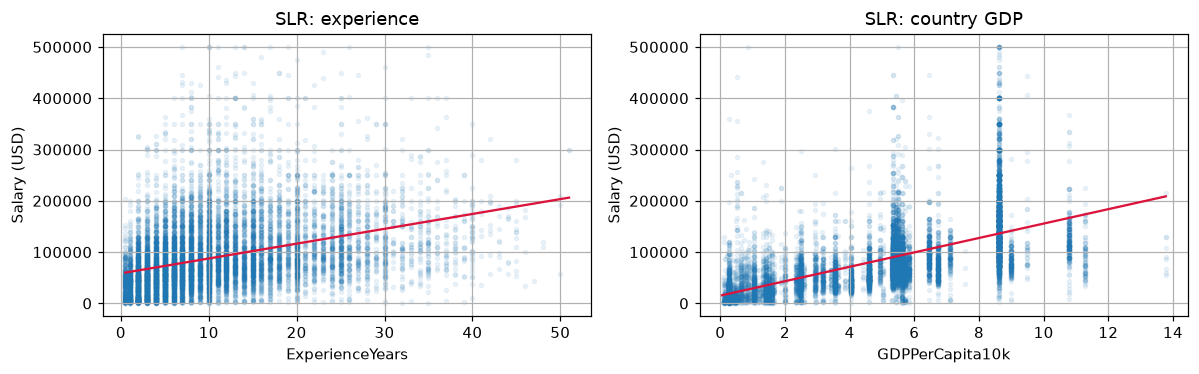

,Predictors,F-statistic,F p-value,Train R2,Adjusted R2,Test R2,Train RMSE (USD),Test RMSE (USD),Negative test predictions
Model,,,,,,,,,
SLR: experience,1,"1,947.328",0.000,0.134,0.134,0.118,"62,722.615","62,104.431",0
SLR: country GDP,1,"7,479.527",0.000,0.372,0.372,0.363,"53,399.046","52,773.340",0


**SLR: country GDP performs better on this test set.** Its test RMSE is USD 52,773, a 15.0% lower error than the other simple model. Its test R² is 0.363. A significant F-test alone does not imply accurate predictions. These are associations, not promised salary increases.

In [12]:
analysis = RegressionStudy()
models, rows = {}, []
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (label, name) in zip(axes, [("SLR: experience", "ExperienceYears"), ("SLR: country GDP", "GDPPerCapita10k")]):
    model = analysis.fit(train[[name]], y_train)
    models[label] = model
    rows.append(analysis.evaluate(label, model, train[[name]], test[[name]], y_train, y_test))
    ax.scatter(train[name], y_train, s=7, alpha=.08)
    grid = pd.DataFrame({name: np.linspace(train[name].min(), train[name].max(), 100)})
    ax.plot(grid[name], analysis.predict(model, grid), color="crimson")
    ax.set(xlabel=name, ylabel="Salary (USD)", title=label)
plt.tight_layout()
plt.show()
simple = pd.DataFrame(rows).set_index("Model")
display(simple)
winner = simple["Test RMSE (USD)"].idxmin()
loser = simple["Test RMSE (USD)"].idxmax()
gain = 100 * (1 - simple.loc[winner, "Test RMSE (USD)"] / simple.loc[loser, "Test RMSE (USD)"])
display(Markdown(f"**{winner} performs better on this test set.** Its test RMSE is USD {simple.loc[winner, 'Test RMSE (USD)']:,.0f}, "
                 f"a {gain:.1f}% lower error than the other simple model. Its test R² is {simple.loc[winner, 'Test R2']:.3f}. "
                 "A significant F-test alone does not imply accurate predictions. These are associations, not promised salary increases."))

### Simple Linear Regression Discussion

Both models are statistically significant, but the GDP
per capita model performs better.

The GDP model has a higher F-statistic and explains 37.2%
of salary variation in the training dataset, compared to
13.4% for the experience model.

The testing RMSE is $52,773 for the GDP model and $62,104
for the experience model. Both models have similar
training and testing errors, suggesting no strong
evidence of overfitting.

Therefore, we select GDP per capita as the better simple
regression model because it explains more salary
variation and has lower prediction error.

## 8. Full model and backward selection
Start with all encoded study predictors. Remove the largest p-value above 0.05 and refit until the rule is met. We select this simpler model before evaluating its test performance. The removal log is the evidence for the selection; it is not a search for the lowest test error.

In [13]:
full_model = analysis.fit(X_train, y_train)
final_model, selected, selection_log = analysis.backward(X_train, y_train, alpha=.05)
print(f"Predictors: {X_train.shape[1]} full -> {len(selected)} final")
print(f"Training adjusted R²: {full_model.rsquared_adj:.4f} full -> {final_model.rsquared_adj:.4f} final")
display(selection_log)
# Show the selected coefficients without printing a long regression summary.
coefficients = pd.DataFrame({"Coefficient (USD)": final_model.params, "p-value": final_model.pvalues})
display(coefficients)

Predictors: 64 full -> 42 final
Training adjusted R²: 0.5385 full -> 0.5385 final


,Step,Removed predictor,p-value,Adjusted R2 before removal
0,1,WorkMode__In_person,0.999,0.538
1,2,CompanySize__Unknown,0.889,0.539
2,3,Industry__Media___Advertising_Services,0.795,0.539
3,4,Industry__Internet__Telecomm_or_Information_Se...,0.812,0.539
4,5,InternetUsersPct,0.800,0.539
5,6,WorkMode__Unknown,0.678,0.539
6,7,Role__Unknown,0.647,0.539
7,8,Industry__Computer_Systems_Design_and_Services,0.631,0.539
8,9,Education__Primary_elementary_school,0.623,0.539
9,10,ReportedDocker,0.523,0.539


,Coefficient (USD),p-value
const,"2,897.638",0.124
ExperienceYears,"1,825.713",0.000
GDPPerCapita10k,"14,353.075",0.000
BroadbandPer100,-632.830,0.000
ReportedPython,"2,740.308",0.002
ReportedJavaScript,"-6,144.780",0.000
ReportedTypeScript,"4,037.265",0.000
ReportedSQL,"-4,758.933",0.000
ReportedJava,"-2,712.076",0.004
ReportedCSharp,"-6,553.723",0.000


## 9. Test the Selected Model

We compare the full and selected multiple linear regression
models with the two simple regression models using the
same testing dataset.

We evaluate their performance using the F-statistic,
R², adjusted R², and training and testing RMSE.

,Predictors,F-statistic,F p-value,Train R2,Adjusted R2,Test R2,Train RMSE (USD),Test RMSE (USD),Negative test predictions
Model,,,,,,,,,
SLR: experience,1,"1,947.328",0.000,0.134,0.134,0.118,"62,722.615","62,104.431",0
SLR: country GDP,1,"7,479.527",0.000,0.372,0.372,0.363,"53,399.046","52,773.340",0
MLR: full,64,231.154,0.000,0.541,0.538,0.514,"45,662.858","46,090.741",65
MLR: selected,42,351.777,0.000,0.540,0.539,0.513,"45,700.506","46,128.302",62


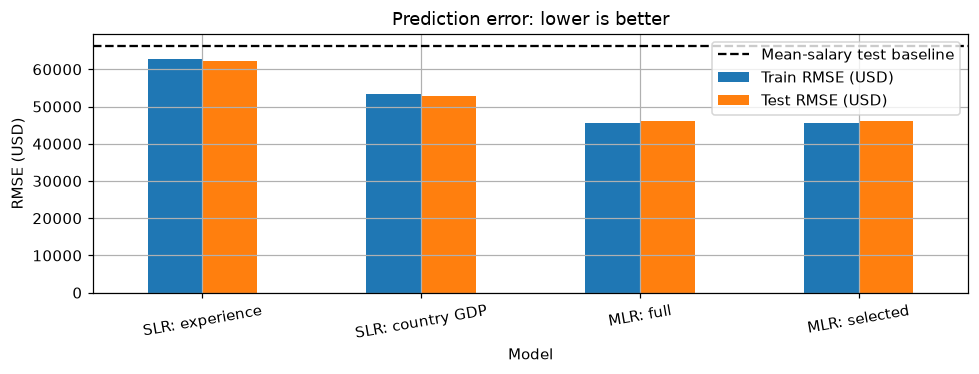

**Selected model:** test RMSE **USD 46,128**, test R² **0.513**. The baseline RMSE is USD 66,128. Selected-minus-full test RMSE is USD 38 (positive means the full model has lower error). We accept the simpler training-selected model with its stated limits.

In [14]:
rows.append(analysis.evaluate("MLR: full", full_model, X_train, X_test, y_train, y_test))
rows.append(analysis.evaluate("MLR: selected", final_model, X_train[selected], X_test[selected], y_train, y_test))
comparison = pd.DataFrame(rows).set_index("Model")
display(comparison)
baseline = np.sqrt(mean_squared_error(y_test, np.repeat(y_train.mean(), len(y_test))))
comparison[["Train RMSE (USD)", "Test RMSE (USD)"]].plot.bar(figsize=(9, 3.5), rot=10)
plt.axhline(baseline, color="black", linestyle="--", label="Mean-salary test baseline")
plt.ylabel("RMSE (USD)")
plt.title("Prediction error: lower is better")
plt.legend()
plt.tight_layout()
plt.show()
final = comparison.loc["MLR: selected"]
difference = final["Test RMSE (USD)"] - comparison.loc["MLR: full", "Test RMSE (USD)"]
display(Markdown(f"**Selected model:** test RMSE **USD {final['Test RMSE (USD)']:,.0f}**, test R² **{final['Test R2']:.3f}**. "
                 f"The baseline RMSE is USD {baseline:,.0f}. Selected-minus-full test RMSE is USD {difference:,.0f} "
                 "(positive means the full model has lower error). We accept the simpler training-selected model with its stated limits."))

### Multiple Linear Regression Discussion

We started with 64 predictors and used backward elimination
to remove 22 predictors based on their training p-values.

The final model contains 42 predictors, with an F-statistic
of 351.78 and an adjusted R² of approximately 0.539.

The training RMSE is $45,701, and the testing RMSE is
$46,128. The model explains 51.3% of salary variation
in the testing dataset.

Although the full model has a slightly lower testing RMSE,
the difference is only about $38. We select the final model
because it uses fewer predictors while maintaining similar
performance.

The final model also performs better than both simple
linear regression models.

## 10. Check Errors and Conclude

We examine the residual plots and prediction errors
to evaluate the final model and identify its limitations.

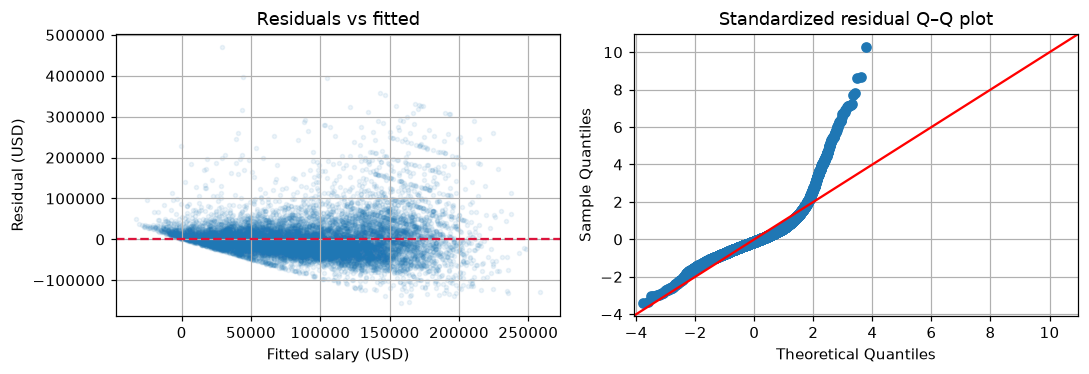

**Conclusion:** We combined two sources for **15,782 respondents**. **SLR: country GDP** was the stronger simple model. Backward selection retained **42** encoded predictors. The final test R² is **0.513**, with an RMSE of **USD 46,128**. There are **62 negative test predictions**, reported without clipping. The saved plots show unequal error spread and a heavy upper tail, so OLS assumptions are not well supported. The model describes sample patterns, but it is not reliable enough to set an individual's salary.

In [15]:
predictions = analysis.predict(final_model, X_test[selected])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(final_model.fittedvalues, final_model.resid, s=7, alpha=.08)
axes[0].axhline(0, color="crimson", linestyle="--")
axes[0].set(xlabel="Fitted salary (USD)", ylabel="Residual (USD)", title="Residuals vs fitted")
sm.qqplot(final_model.resid / np.sqrt(final_model.mse_resid), line="45", ax=axes[1])
axes[1].set_title("Standardized residual Q–Q plot")
plt.tight_layout()
plt.show()
negative = int((predictions < 0).sum())
display(Markdown(
    f"**Conclusion:** We combined two sources for **{len(study):,} respondents**. "
    f"**{winner}** was the stronger simple model. Backward selection retained **{len(selected)}** encoded predictors. "
    f"The final test R² is **{final['Test R2']:.3f}**, with an RMSE of **USD {final['Test RMSE (USD)']:,.0f}**. "
    f"There are **{negative} negative test predictions**, reported without clipping. "
    "The saved plots show unequal error spread and a heavy upper tail, so OLS assumptions are not well supported. "
    "The model describes sample patterns, but it is not reliable enough to set an individual's salary."
))

### Final Conclusion

The results show that GDP per capita is a better individual
predictor of annual salary than professional experience.

The selected multiple linear regression model provides better
predictions than both simple regression models. It contains
42 predictors and explains 51.3% of salary variation in the
testing dataset.

However, the model produces 62 negative salary predictions,
which shows that it has limitations.

Overall, professional experience, job characteristics,
technical skills, and country-level conditions help explain
salary differences among technology professionals.

**Limits:** answers are voluntary and self-reported; filters exclude some real salaries and incomplete responses; related predictors can share information; country values repeat across respondents; and USD salaries are not adjusted for living costs. The split evaluates respondents in a similar country mix, not unseen countries. Associations are not causes, and fairness has not been established.

**Presentation:** explain the question and preparation (1½ min), split (½ min), simple models (1½ min), full/selected model (1 min), test comparison (1 min), and errors/conclusion (1½ min). Use the three figures instead of reading code aloud.

**Submission:** Restart the kernel, run all cells, and save
the notebook with its outputs. Submit the same `.ipynb` file
without zipping and include the GitHub repository link.

Each team member must submit their individual feedback form.